# 03 — Feature Engineering, Preprocessing and Leakage Audit

This notebook builds the model-ready dataset and **checks for data leakage before any model is trained**.

**Prediction setting.** For household *h* and billing month *t*, predict the bill (kWh) at the start of month *t*,
using only bills up to *t − 1*, plus Wave 1 survey answers *only if* the interview took place before that date.

**Sections:** 1 Verifying the removed households · 2 Feature table · 3 Survey availability over time ·
4 Train / validation / test design · 5 Preprocessing pipeline · 6 Leakage audit · 7 Summary

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import plot_style as ps
from src.data_loader import load_monthly_consumption, load_survey_dates, load_survey_table, CONSUMPTION_UNIT as U
from src.data_processing import build_household_features_w1
from src.feature_engineering import (build_feature_table, add_history_features, FEATURE_SETS, FEATURE_DESCRIPTIONS,
                                     HISTORY_FEATURES, CALENDAR_FEATURES, SURVEY_NUMERIC, SURVEY_CATEGORICAL, FORBIDDEN_FEATURES)
from src.validation import (modelling_rows, train_test_split_time, expanding_month_folds, unseen_household_folds,
                            TRAIN_END, TEST_START, TEST_END, FIRST_TARGET_MONTH)
from src.preprocessing import build_preprocessor, model_input_columns
ps.apply(); pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
P = ROOT / "data" / "processed"
m = pd.read_parquet(P / "monthly_clean.parquet")
hf = pd.read_parquet(P / "household_features_w1.parquet")
sd = load_survey_dates()
print(json.loads((P / "cleaning_log.json").read_text()))

{'input_rows': 101575, 'input_households': 4063, 'missing_readings_in_input': 590, 'always_zero_households_removed_invalid': 15, 'low_activity_households_kept_and_flagged': 19, 'output_rows': 101200, 'output_households': 4048, 'missing_readings_kept_as_nan': 571, 'zero_months_kept': 1976, 'isolated_spikes_flagged': 18, 'household_features_rows': 4063, 'household_features_columns': 50}


## 1. Verifying the 15 removed always-zero households

Decision: remove only households whose bill is zero in *every* recorded month, **after verifying** that
they are inactive or invalid records. Below, each one is checked against the Wave 1 survey and the 15-minute
smart-meter data.

In [2]:
raw = load_monthly_consumption()
mx = raw.groupby("household_ID").consumption.max()
ids = mx[(mx == 0) | mx.isna()].index
f = build_household_features_w1().set_index("household_ID").loc[ids]
daily = pd.read_parquet(P / "smart_daily.parquet").groupby("household_ID").kwh.agg(["size", "median"])
check = pd.DataFrame({
    "months_recorded": raw[raw.household_ID.isin(ids)].groupby("household_ID").consumption.count(),
    "members (W1)": f.household_size, "appliances (W1)": f.n_appliances_total, "refrigerators (W1)": f.n_refrigerator,
    "meter type (W1)": f.meter_type,
    "15-min complete days": daily.reindex(ids)["size"], "15-min median kWh/day": daily.reindex(ids)["median"],
})
display(check)
print(f"All occupied (≥1 member): {(check['members (W1)'] >= 1).all()} | all own a refrigerator: {(check['refrigerators (W1)'] >= 1).all()}")
print(f"Households with 15-minute data: {check['15-min complete days'].notna().sum()}, all reading 0 kWh/day: "
      f"{(check['15-min median kWh/day'].dropna() == 0).all()}")

,months_recorded,members (W1),appliances (W1),refrigerators (W1),meter type (W1),15-min complete days,15-min median kWh/day
household_ID,,,,,,,
ID0080,25,7,10.0,1.0,Non smart meter,NaN,NaN
ID0109,21,4,24.0,1.0,Smart meter,NaN,NaN
ID0167,25,3,28.0,1.0,Non smart meter,NaN,NaN
ID0393,25,3,23.0,1.0,Smart meter,NaN,NaN
ID0712,25,2,10.0,1.0,Non smart meter,NaN,NaN
ID1405,25,3,23.0,1.0,Non smart meter,NaN,NaN
ID1849,25,1,13.0,1.0,Smart meter,195.0,0.0
ID1986,25,5,27.0,1.0,Smart meter,156.0,0.0
ID2125,25,6,14.0,1.0,Smart meter,99.0,0.0


All occupied (≥1 member): True | all own a refrigerator: True
Households with 15-minute data: 7, all reading 0 kWh/day: True


**Conclusion.** These are **invalid records, not vacant homes**. Every one was an occupied household with a refrigerator
in Wave 1 — such a home cannot use zero electricity for 25 months — and where 15-minute data exist, the linked meter
also records nothing. The meter linked to these households is therefore not their actual supply (a meter–household
linkage error). They are removed from all experiments. The 19 households that never exceed 5 kWh are **kept** and
flagged for robustness experiment R1.

In [3]:
low = m[m.is_low_activity_household].groupby("household_ID").consumption.agg(["max", "mean", "count"])
print("Low-activity households kept (flagged):", len(low)); low.round(1).T

Low-activity households kept (flagged): 19


household_ID,ID0021,ID0122,ID0460,ID0677,ID0856,ID0874,ID0903,ID1783,ID1963,ID2124,ID2162,ID2256,ID2325,ID2373,ID2478,ID2863,ID2980,ID3764,ID3910
max,3.0,2.0,3.0,1.0,2.0,1.0,3.0,2.0,5.0,2.0,2.0,3.0,2.0,4.0,1.0,1.0,5.0,3.0,5.0
mean,0.5,0.3,0.8,0.0,0.1,0.0,1.0,0.1,1.4,0.1,0.2,0.3,0.5,1.4,0.1,0.1,0.6,0.6,1.3
count,25.0,24.0,25.0,25.0,25.0,25.0,25.0,25.0,25.0,25.0,25.0,25.0,25.0,25.0,25.0,25.0,25.0,25.0,25.0


## 2. The feature table
### 2.1 Feature definitions

In [4]:
groups = {**{c: "History (bills up to t-1)" for c in HISTORY_FEATURES}, **{c: "Calendar" for c in CALENDAR_FEATURES},
          "survey_available": "Survey availability flag"}
pd.DataFrame({"group": pd.Series(groups), "description": pd.Series(FEATURE_DESCRIPTIONS)}).rename_axis("feature")

,group,description
feature,,
lag_1,History (bills up to t-1),"Bill of the previous month (t-1), kWh"
lag_2,History (bills up to t-1),"Bill two months before (t-2), kWh"
lag_3,History (bills up to t-1),"Bill three months before (t-3), kWh"
lag_6,History (bills up to t-1),"Bill six months before (t-6), kWh"
lag_12,History (bills up to t-1),Bill of the same billing month last year (t-12...
roll_mean_3,History (bills up to t-1),Mean of the bills t-3..t-1 (observed months on...
roll_mean_6,History (bills up to t-1),"Mean of the bills t-6..t-1, kWh"
roll_median_3,History (bills up to t-1),Median of the bills t-3..t-1 — robust to a sin...
roll_std_6,History (bills up to t-1),Standard deviation of the bills t-6..t-1 — how...


Plus **31 numeric and 7 categorical Wave 1 survey features** (household size, floor area, appliance counts, AC/fan/bulb
usage, socio-economic class, house type, CSC area, …), each **masked** when the survey was not yet available.

**Why these history features?** Notebook 02 showed that ~85% of the variance is *between* households and that last
month's bill alone correlates 0.93 with this month's. Lags capture the household's level; rolling means/medians
smooth out noise and single spikes; `roll_std_6` describes stability; `lag_12` captures the same billing month last
year (seasonality); zero/missing counts tell the model when recent history is unreliable.

**Why no year/trend feature?** Tree models cannot extrapolate a trend to test months whose year/time index is larger
than anything seen in training, and a time index would let a model memorise period effects. Calendar month (cyclic
sin/cos) is used instead.

In [5]:
F = build_feature_table(m, hf, sd)
print("Feature table:", F.shape, "| one row per household-month:", not F.duplicated(["household_ID", "month"]).any())
show = ["month", "consumption", "lag_1", "lag_2", "lag_3", "roll_mean_3", "roll_median_3", "hist_mean", "change_1",
        "missing_count_6", "survey_available"]
print("Example household (first 8 months) — each row's features use only the rows ABOVE it:")
F[F.household_ID == "ID0001"][show].head(8).set_index("month").round(1)

Feature table: (101200, 64) | one row per household-month: True
Example household (first 8 months) — each row's features use only the rows ABOVE it:


,consumption,lag_1,lag_2,lag_3,roll_mean_3,roll_median_3,hist_mean,change_1,missing_count_6,survey_available
month,,,,,,,,,,
2022-10-01,116.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2022-11-01,120.0,116.0,NaN,NaN,116.0,116.0,116.0,NaN,0.0,0
2022-12-01,129.0,120.0,116.0,NaN,118.0,118.0,118.0,4.0,0.0,0
2023-01-01,102.0,129.0,120.0,116.0,121.7,120.0,121.7,9.0,0.0,0
2023-02-01,115.0,102.0,129.0,120.0,117.0,120.0,116.8,-27.0,0.0,0
2023-03-01,97.0,115.0,102.0,129.0,115.3,115.0,116.4,13.0,0.0,0
2023-04-01,94.0,97.0,115.0,102.0,104.7,102.0,113.2,-18.0,0.0,0
2023-05-01,98.0,94.0,97.0,115.0,102.0,97.0,110.4,-3.0,0.0,0


## 3. Survey availability over time

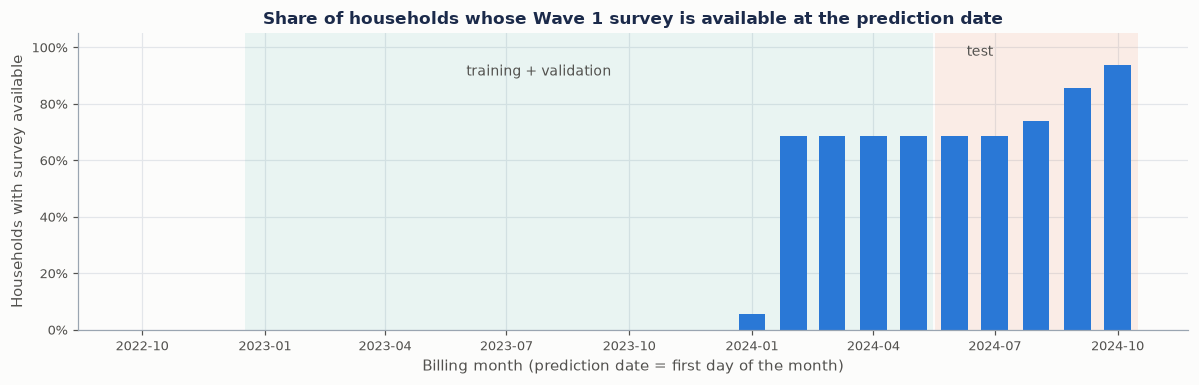

Survey available — training rows: 16.4% | test rows: 78.1%
{'2023-12': 0.0, '2024-01': 0.055, '2024-02': 0.686, '2024-03': 0.686, '2024-04': 0.686, '2024-05': 0.686, '2024-06': 0.686, '2024-07': 0.686, '2024-08': 0.739, '2024-09': 0.856, '2024-10': 0.936}


In [6]:
av = F.groupby("month").survey_available.mean()
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.axvspan(FIRST_TARGET_MONTH - pd.Timedelta(days=15), TRAIN_END + pd.Timedelta(days=15), color=ps.TEAL, alpha=0.08, lw=0)
ax.axvspan(TEST_START - pd.Timedelta(days=15), TEST_END + pd.Timedelta(days=15), color=ps.ORANGE, alpha=0.10, lw=0)
ax.bar(av.index, av.values, width=20, color=ps.BLUE)
ax.text(pd.Timestamp("2023-06-01"), 0.9, "training + validation", color=ps.INK_2, fontsize=9)
ax.text(pd.Timestamp("2024-06-10"), 0.97, "test", color=ps.INK_2, fontsize=9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_ylim(0, 1.05)
ax.set(title="Share of households whose Wave 1 survey is available at the prediction date",
       xlabel="Billing month (prediction date = first day of the month)", ylabel="Households with survey available")
plt.tight_layout(); plt.show()
rows = modelling_rows(F); train, test = train_test_split_time(rows)
print(f"Survey available — training rows: {train.survey_available.mean():.1%} | test rows: {test.survey_available.mean():.1%}")
print(av[av.index >= "2023-12-01"].round(3).rename(lambda d: d.strftime("%Y-%m")).to_dict())

**Interpretation.** Because survey answers may only be used *after* the interview, they are unavailable for all of
2023, become available for ~69% of households from February 2024, and for ~94% by October 2024. A model can learn
survey effects only from Jan–May 2024 training rows (~16% of training rows), while most test rows have survey data.
This is the honest cost of strict leakage control: it is likely to limit how much the survey features can help, and it
is why the **history-only model is the main model**. The comparison with history + survey will measure the
added value under these realistic conditions.

## 4. Train / validation / test design

In [7]:
summary = pd.DataFrame({
    "period": ["Training + validation", "Test (untouched)"],
    "billing months": [f"{train.month.min():%Y-%m} … {train.month.max():%Y-%m}", f"{test.month.min():%Y-%m} … {test.month.max():%Y-%m}"],
    "months": [train.month.nunique(), test.month.nunique()], "rows": [len(train), len(test)],
    "households": [train.household_ID.nunique(), test.household_ID.nunique()],
    f"mean target ({U})": [train.consumption.mean(), test.consumption.mean()],
})
display(summary.round(1))
excluded = F[(F.month >= FIRST_TARGET_MONTH) & F.consumption.isna()]
print(f"Rows not used as examples because the target is missing: {len(excluded)}")
folds = [{"fold": i + 1, "train months": f"{train.month.iloc[a].min():%Y-%m} … {train.month.iloc[a].max():%Y-%m}",
          "train rows": len(a), "validation month": f"{train.month.iloc[b].min():%Y-%m}", "validation rows": len(b),
          "survey available in fold training rows": f"{train.survey_available.iloc[a].mean():.1%}"}
         for i, (a, b) in enumerate(expanding_month_folds(train))]
print("Expanding-window one-month-ahead tuning folds (inside the training period only):")
pd.DataFrame(folds)

,period,billing months,months,rows,households,mean target (kWh)
0,Training + validation,2023-01 … 2024-05,17,68485,4048,121.3
1,Test (untouched),2024-06 … 2024-10,5,20094,4030,129.7


Rows not used as examples because the target is missing: 477
Expanding-window one-month-ahead tuning folds (inside the training period only):


,fold,train months,train rows,validation month,validation rows,survey available in fold training rows
0,1,2023-01 … 2023-12,48373,2024-01,4022,0.0%
1,2,2023-01 … 2024-01,52395,2024-02,4023,0.4%
2,3,2023-01 … 2024-02,56418,2024-03,4024,5.3%
3,4,2023-01 … 2024-03,60442,2024-04,4021,9.5%
4,5,2023-01 … 2024-04,64463,2024-05,4022,13.2%


**Rolling one-month-ahead testing.** A single model trained on Jan 2023 – May 2024 predicts each test month in turn.
For July 2024, `lag_1` is the *actual* June 2024 bill — known before July's prediction is made, and June's own
prediction has already been evaluated. A test month's bill is never used to predict itself or any earlier month.

**Scenario B — unseen households.** Households are split into 5 groups. A model is trained on training-period rows of
4 groups and evaluated on test-period rows of the 5th group:

In [8]:
sb = [{"fold": i + 1, "training households": train.household_ID[tr].nunique(), "training rows": int(tr.sum()),
       "held-out households": test.household_ID[te].nunique(), "held-out test rows": int(te.sum()),
       "overlap": len(set(train.household_ID[tr]) & set(test.household_ID[te]))}
      for i, (tr, te) in enumerate(unseen_household_folds(train, test))]
pd.DataFrame(sb)

,fold,training households,training rows,held-out households,held-out test rows,overlap
0,1,3238,54752,808,4025,0
1,2,3238,54791,808,4028,0
2,3,3238,54794,804,4003,0
3,4,3239,54773,806,4022,0
4,5,3239,54830,804,4016,0


## 5. Preprocessing pipeline (fitted on training rows only)

In [9]:
for fs in FEATURE_SETS:
    cols = model_input_columns(fs)
    pre = build_preprocessor(fs, scale=True).fit(train[cols])
    Xtr, Xte = pre.transform(train[cols]), pre.transform(test[cols])
    names = pre.get_feature_names_out()
    print(f"{fs:22s} raw inputs: {len(cols):3d} -> model columns: {Xtr.shape[1]:3d} "
          f"(missing indicators: {sum('missingindicator' in n for n in names)}, one-hot: {sum(n.startswith('survey_cat') for n in names)}) "
          f"| NaN after preprocessing: train {int(np.isnan(Xtr).sum())}, test {int(np.isnan(Xte).sum())}")
pre_h = build_preprocessor("history_only", scale=True)
print("\nPipeline structure (history-only, linear-model version):"); pre_h

history_only           raw inputs:  17 -> model columns:  29 (missing indicators: 12, one-hot: 0) | NaN after preprocessing: train 0, test 0


history_plus_survey    raw inputs:  56 -> model columns: 123 (missing indicators: 12, one-hot: 62) | NaN after preprocessing: train 0, test 0
diag_no_calendar       raw inputs:  14 -> model columns:  26 (missing indicators: 12, one-hot: 0) | NaN after preprocessing: train 0, test 0


diag_no_calendar_no_lag12 raw inputs:  13 -> model columns:  24 (missing indicators: 11, one-hot: 0) | NaN after preprocessing: train 0, test 0

Pipeline structure (history-only, linear-model version):


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('history', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``"

## 6. Leakage audit on the real data

Each check is run on the real feature table. The same rules are also enforced by automated tests
(`tests/test_feature_leakage.py`, `tests/test_preprocessing.py`).

In [10]:
results = []
def record(name, passed, detail):
    results.append({"check": name, "result": "PASS" if passed else "FAIL", "detail": detail})

# 1. Lags equal the actual past bills
s = F.sample(2000, random_state=0); actual = F.set_index(["household_ID", "month"]).consumption
ok = all(((np.isnan(r.lag_1) and np.isnan(actual.get((r.household_ID, r.month - pd.DateOffset(months=1)), np.nan)))
          or r.lag_1 == actual.get((r.household_ID, r.month - pd.DateOffset(months=1)), np.nan)) for r in s.itertuples())
record("lag_1 equals the actual bill of month t-1", ok, "2,000 random rows")

# 2. Changing the target month and everything after it does not change earlier features
for cut in [pd.Timestamp("2024-01-01"), TEST_START, pd.Timestamp("2024-08-01")]:
    q = m.copy(); fut = q.month >= cut
    q.loc[fut, "consumption"] = q.loc[fut, "consumption"] * 5 + 777
    a = add_history_features(m).set_index(["household_ID", "month"])[HISTORY_FEATURES]
    b = add_history_features(q).set_index(["household_ID", "month"])[HISTORY_FEATURES]
    early = a.index.get_level_values("month") <= cut
    same = a[early].equals(b[early]); changed_later = not a[~early].equals(b[~early])
    record(f"Features of months ≤ {cut:%Y-%m} unaffected by changing bills ≥ {cut:%Y-%m}", same and changed_later,
           f"{early.sum():,} rows identical; later rows do change: {changed_later}")

# 3. Survey availability
on = F.survey_available == 1
record("Survey used only when interview date < first day of billing month", bool((F.wave1_date[on] < F.month[on]).all()), f"{on.sum():,} rows with survey")
record("Survey features empty whenever unavailable", bool(F.loc[~on, SURVEY_NUMERIC].isna().all().all() and F.loc[~on, SURVEY_CATEGORICAL].isna().all().all()), f"{(~on).sum():,} rows")
record("No Wave 2 / Wave 3 information in the feature table", not any(c.startswith(("w2", "w3", "wave2", "wave3")) for c in F.columns), "column names checked")

# 4. Forbidden inputs
inputs = set().union(*[set(model_input_columns(fs)) for fs in FEATURE_SETS])
record("No identifier, target or data-quality flag is a model input", not inputs & FORBIDDEN_FEATURES, ", ".join(sorted(FORBIDDEN_FEATURES)))

# 5. Time separation
record("All training months before all test months", train.month.max() < test.month.min(), f"train ≤ {train.month.max():%Y-%m}, test ≥ {test.month.min():%Y-%m}")
record("Every tuning fold validates on a later month than it trains on",
       all(train.month.iloc[a].max() < train.month.iloc[b].min() for a, b in expanding_month_folds(train)), "5 folds")
record("Unseen-household folds share no households",
       all(not set(train.household_ID[tr]) & set(test.household_ID[te]) for tr, te in unseen_household_folds(train, test)), "5 folds")

# 6. Preprocessing statistics come from training rows only
pre = build_preprocessor("history_only").fit(train[model_input_columns("history_only")])
imp = pre.named_transformers_["history"].named_steps["impute"]; cols = pre.transformers_[0][2]
tr_med = train[cols].median().to_numpy(); all_med = rows[cols].median().to_numpy()
record("Imputation medians equal TRAINING medians (not full-data medians)", np.allclose(imp.statistics_, tr_med),
       f"{int((~np.isclose(tr_med, all_med)).sum())} of {len(cols)} medians would differ if test rows were included")

# 7. Targets
record("No missing targets in training or test examples", train.consumption.notna().all() and test.consumption.notna().all(), f"{len(train):,} + {len(test):,} rows")
audit = pd.DataFrame(results); audit.index += 1
print(f"{(audit.result == 'PASS').sum()} of {len(audit)} checks passed"); audit

13 of 13 checks passed


,check,result,detail
1,lag_1 equals the actual bill of month t-1,PASS,"2,000 random rows"
2,Features of months ≤ 2024-01 unaffected by cha...,PASS,"64,768 rows identical; later rows do change: True"
3,Features of months ≤ 2024-06 unaffected by cha...,PASS,"85,008 rows identical; later rows do change: True"
4,Features of months ≤ 2024-08 unaffected by cha...,PASS,"93,104 rows identical; later rows do change: True"
5,Survey used only when interview date < first d...,PASS,"27,116 rows with survey"
6,Survey features empty whenever unavailable,PASS,"74,084 rows"
7,No Wave 2 / Wave 3 information in the feature ...,PASS,column names checked
8,"No identifier, target or data-quality flag is ...",PASS,"consumption, household_ID, is_isolated_spike, ..."
9,All training months before all test months,PASS,"train ≤ 2024-05, test ≥ 2024-06"
10,Every tuning fold validates on a later month t...,PASS,5 folds


In [11]:
# Re-run the automated test suite from the notebook for a complete record
import subprocess
r = subprocess.run([sys.executable, "-m", "pytest", "-q", str(ROOT / "tests")], capture_output=True, text=True, cwd=ROOT)
print(r.stdout.strip().splitlines()[-1])

36 passed in 27.42s


### Leakage risks considered and how they are handled

| Risk | How it could leak | Handling |
|---|---|---|
| Lag/rolling features including month *t* | Model sees the answer | All built from `shift(k ≥ 1)`; perturbation checks above |
| Future survey waves | Waves 2/3 collected after the data end | Excluded (D3) |
| Wave 1 used before interview | Household characteristics "from the future" | Date mask (D4) |
| Random train/test split | Future months in training | Chronological split; identical test months for every model |
| Preprocessing fitted on all data | Test statistics influence training | Pipeline fitted on training rows only |
| Tuning on the test set | Optimistic test score | Tuning folds inside Jan 2023 – May 2024 only |
| Spike flag / current-month flags as features | Flag computed with the next month | Listed in `FORBIDDEN_FEATURES`; tested |
| `household_ID` as a numeric feature | Memorising arbitrary IDs | Never an input; used only for grouping |
| Stacking with shuffled internal CV | Base-model predictions from future months | To be addressed in notebook 05 with time-ordered out-of-fold predictions |

## 7. Summary

* 15 always-zero households verified as invalid records and removed; 19 low-activity households kept and flagged.
* Feature table: one row per household-month; 14 history + 3 calendar features (history-only model) and 39 date-masked
  Wave 1 survey features (history + survey model).
* Training + validation: Jan 2023 – May 2024; untouched test: Jun – Oct 2024, predicted one month ahead.
* Survey information is available for only ~16% of training rows but ~78% of test rows — a realistic limitation of
  using survey data without leakage.
* All leakage checks pass on the real data and in the automated tests.

**Next (notebook 04):** baseline models (naive previous-month, DummyRegressor, Linear, Ridge) on the
identical split.